Pearson correlation between attr_mean and gamma: -0.997137
Pearson p-value: 0.000000


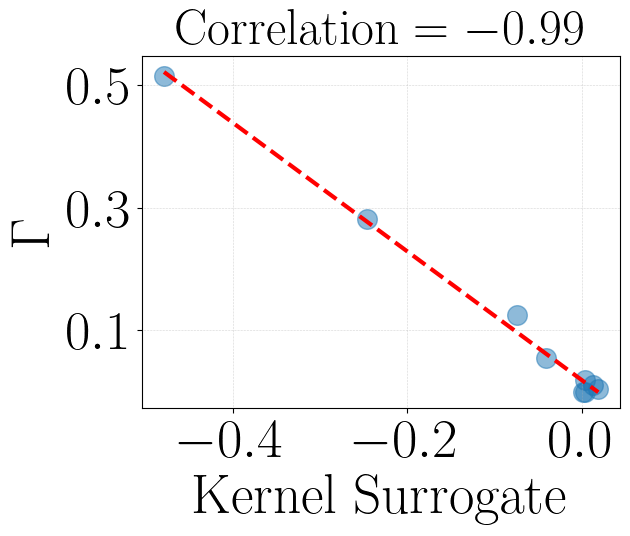

In [12]:

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc
from scipy.stats import pearsonr

rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker

# attr_mean = np.array([-0.4783, -0.075, 0.0026, 0.0027, 0.0009])
# gamma = np.array([0.5158, 0.1244, 0.0188, 0.0003, 0.0])
attr_mean = np.array([-0.4783, -0.2464, -0.075, -0.0412, 0.0026, 0.0027, 0.0009, 0.0125, 0.0182])
gamma = np.array([0.5158, 0.2821, 0.1244, 0.0548, 0.0188, 0.0003, 0.0, 0.0105, 0.0042])
attr_std = np.array([0.012, 0.006, 0.003, 0.001, 0.0006])
# plt.figure(figsize=(6, 5))
# plt.scatter(attr_mean, gamma, color='royalblue', alpha=1, s=400)
# plt.plot(attr_mean, gamma, color='royalblue', linewidth=4, ls='--', label=r'$\mathrm{Attribution}$')
# plt.errorbar(attr_mean, gamma, xerr=attr_std, fmt='none')

coeffs = np.polyfit(attr_mean, gamma, 1)
fit_line = np.poly1d(coeffs)

x_vals = np.linspace(min(attr_mean), max(attr_mean), 500)
y_vals = fit_line(x_vals)

# Compute Pearson correlation
pearson_corr, pearson_p = pearsonr(attr_mean, gamma)

print(f"Pearson correlation between attr_mean and gamma: {pearson_corr:.6f}")
print(f"Pearson p-value: {pearson_p:.6f}")

fig, ax = plt.subplots(figsize=(6.4, 5))
plt.scatter(attr_mean, gamma, s=200, alpha=0.5)
plt.plot(x_vals, y_vals, color='red', lw=3, ls='--', label=f"Fit: y={coeffs[0]:.2e}x + {coeffs[1]:.2e}")

plt.xlabel(r'$\mathrm{Kernel~Surrogate}$', fontsize=40)
plt.ylabel(r'$\Gamma$', fontsize=40)
plt.xticks([-0.4, -0.2, 0.0], fontsize=40)
plt.yticks([0.1, 0.3, 0.5], fontsize=40)
plt.grid(lw=0.4, ls=":")

plt.tight_layout()
title_name = r'$\mathrm{Correlation}=-0.99$'
plt.title(title_name, fontsize=36)


plt.savefig("correlation_ksm_gamma.pdf", format="pdf", dpi=1200, bbox_inches='tight')
plt.show()